# ETF 均值回归：随机森林与 XGBoost

仅使用 2023–2025 年真实事件，按 Y 分层随机划分训练/验证/测试 60%/20%/20%，种子 5001。比较 A、AB、ABC 三组特征，每组分别使用 RF 和 XGBoost，共六组最终模型。

A 为技术与价格状态，B 为 m、sigma_eq、HL，C 为 group_dev、group_size。成交额两列取 log1p，A/B 缺失事件剔除，C 缺失使用训练中位数填补。沿用上游真实事件 Y，不重新生成特征或标签。

流程：读取与划分 → 验证选参 → 测试指标与特征增量 → 模型解释 → 保存。结果写入 results/tree_random/。

逐行随机划分未隔离同日 ETF 和重叠标签窗口，结论限于历史事件分类，不代表独立未来时期的验证。

## 1. 配置与特征

只读取 train.csv（2023–2024）与 validation.csv（2025）；不读取2026年的 test.csv。六组模型使用同一批事件和同一次随机划分，分类阈值统一为0.5。

B 沿用历史250日六因子 OLS 残差的 AR(1) 参数：m 为局部均衡均值，sigma_eq 为均衡波动尺度，HL 为半衰期；计算公式见 README。

In [1]:
from pathlib import Path
import hashlib
import json
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from scipy.special import expit
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier, DMatrix
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, brier_score_loss, log_loss,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEED = 5001
TRAIN_SIZE, VALIDATION_SIZE, TEST_SIZE = 0.6, 0.2, 0.2
START_DATE, END_DATE = '2023-01-01', '2025-12-31'
DATA_DIR = Path('data/events')
INPUT_FILES = ['train', 'validation']
THRESHOLD = 0.5
OUT_DIR = Path('results/tree_random')
FIG_DIR = OUT_DIR / 'figures'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {p: metadata.version(p) for p in ['shap', 'scikit-learn', 'xgboost', 'numpy', 'pandas', 'matplotlib', 'joblib']}

A = ['ret_1', 'ret_5', 'ret_20', 'vol_20', 'rsi_14', 'macd', 'macd_signal',
     'macd_hist', 'log_amount', 'log_adv20_calc', 'bias_20', 'd_T']
B = ['m', 'sigma_eq', 'HL']
C = ['group_dev', 'group_size']
RAW_AB = ['ret_1', 'ret_5', 'ret_20', 'vol_20', 'rsi_14', 'macd', 'macd_signal',
          'macd_hist', 'amount', 'adv20_calc', 'bias_20', 'd_T'] + B
base_feature_sets = {'A': A, 'AB': A+B, 'ABC': A+B+C}
feature_sets = {f'{kind}_{name}': columns for kind in ['RF', 'XGB']
                for name, columns in base_feature_sets.items()}
feature_table = pd.DataFrame({'feature': A+B+C, 'group': ['A']*len(A)+['B']*len(B)+['C']*len(C)})
pd.DataFrame({'model': list(feature_sets), 'n_features': [len(v) for v in feature_sets.values()]})

,model,n_features
0,RF_A,12
1,RF_AB,15
2,RF_ABC,17
3,XGB_A,12
4,XGB_AB,15
5,XGB_ABC,17


## 2. 读取、预处理与随机划分

保留2023–2025年且原始 A/B 特征均有限的共同样本。成交额负值按参考版截为0后取 log1p；C 非有限值转为缺失，留到模型流水线中填补。

两次 train_test_split 均 shuffle=True、stratify=Y：先分60/40，再将40均分验证和测试。original_split仅记录来源，本次split才是模型归属。

In [2]:
source_frames, preprocessing_rows = [], []
input_hashes = {}
for input_name in INPUT_FILES:
    path = DATA_DIR / f'{input_name}.csv'
    input_hashes[str(path)] = hashlib.sha256(path.read_bytes()).hexdigest()
    frame = pd.read_csv(path, dtype={'code': 'string'}, encoding='utf-8-sig')
    frame['date'] = pd.to_datetime(frame['date'], format='mixed', errors='raise')
    for column in RAW_AB+C:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    in_period = frame['date'].between(START_DATE, END_DATE)
    finite_ab = np.isfinite(frame[RAW_AB].to_numpy(dtype=float)).all(axis=1)
    work = frame.loc[in_period & finite_ab].copy()
    work['log_amount'] = np.log1p(work['amount'].clip(lower=0))
    work['log_adv20_calc'] = np.log1p(work['adv20_calc'].clip(lower=0))
    work[C] = work[C].replace([np.inf, -np.inf], np.nan)
    preprocessing_rows.append({
        'source': input_name, 'raw_rows': len(frame), 'rows_in_period': int(in_period.sum()),
        'rows_dropped_for_missing_A_or_B': int((in_period & ~finite_ab).sum()),
        'rows_kept': len(work), 'negative_activity_rows_clipped': int(work[['amount', 'adv20_calc']].lt(0).any(axis=1).sum()),
        'group_dev_missing': int(work['group_dev'].isna().sum()),
        'group_size_missing': int(work['group_size'].isna().sum())})
    source_frames.append(work.rename(columns={'split': 'original_split'}))
FIG_DIR.mkdir(parents=True, exist_ok=True)
preprocessing_summary = pd.DataFrame(preprocessing_rows)
events = pd.concat(source_frames, ignore_index=True).sort_values(['date', 'code']).reset_index(drop=True)
events['sample_id'] = events['date'].dt.strftime('%Y-%m-%d') + '_' + events['code']
train_index, holdout_index = train_test_split(
    events.index.to_numpy(), test_size=VALIDATION_SIZE+TEST_SIZE,
    random_state=SEED, shuffle=True, stratify=events['Y'])
validation_index, test_index = train_test_split(
    holdout_index, test_size=TEST_SIZE/(VALIDATION_SIZE+TEST_SIZE),
    random_state=SEED, shuffle=True, stratify=events.loc[holdout_index, 'Y'])
tables = {name: events.loc[index].copy().assign(split=name).reset_index(drop=True)
          for name, index in [('train', train_index), ('validation', validation_index), ('test', test_index)]}
train, validation, test = (tables[s] for s in ['train', 'validation', 'test'])
sample_summary = pd.DataFrame([
    {'split': name, 'events': len(frame), 'etfs': frame['code'].nunique(),
     'success_rate': frame['Y'].mean(), 'fraction': len(frame)/len(events),
     'date_min': frame['date'].min(), 'date_max': frame['date'].max(),
     'group_dev_missing_rate': frame['group_dev'].isna().mean(),
     'group_size_missing_rate': frame['group_size'].isna().mean()}
    for name, frame in tables.items()])
split_assignments = pd.concat([
    frame[['sample_id', 'date', 'code', 'original_split', 'split', 'Y']] for frame in tables.values()
], ignore_index=True)
print(f'2023–2025 可用事件 {len(events)}；保留 C 缺失事件 {events[C].isna().any(axis=1).sum()}。')
sample_summary

2023–2025 可用事件 5627；保留 C 缺失事件 532。


,split,events,etfs,success_rate,fraction,date_min,date_max,group_dev_missing_rate,group_size_missing_rate
0,train,3376,315,0.607524,0.599964,2023-02-02,2025-12-03,0.095379,0.095379
1,validation,1125,280,0.608000,0.199929,2023-02-02,2025-12-03,0.096000,0.096000
2,test,1126,283,0.607460,0.200107,2023-02-02,2025-12-01,0.090586,0.090586


## 3. 拟合六组模型，验证集选参

每条流水线为训练中位数填补器 → RF/XGB。验证和测试仅应用训练集统计量，不标准化。

保留原参数网格：RF每组12个候选，XGB每组24个候选。三个特征组共108次候选拟合，保留六个最终模型。按验证Log Loss最小选择，并列时优先AUC更高；不合并验证集重训，测试不参与选择。

In [3]:
def make_model(kind, params):
    if kind == 'RF':
        classifier = RandomForestClassifier(**params, random_state=SEED, n_jobs=2)
    else:
        classifier = XGBClassifier(
            **params, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
            objective='binary:logistic', eval_metric='logloss', tree_method='hist',
            random_state=SEED, n_jobs=2, verbosity=0)
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', classifier)])

parameter_grids = {
    'RF': [{'n_estimators': 300, 'max_depth': depth, 'min_samples_leaf': leaf, 'max_features': mf}
           for depth in [3, 6, None] for leaf in [5, 20] for mf in ['sqrt', 0.7]],
    'XGB': [{'n_estimators': n, 'max_depth': depth, 'learning_rate': lr, 'min_child_weight': child}
            for n in [100, 300] for depth in [2, 3, 4] for lr in [0.03, 0.05] for child in [5, 10]]
}

models, selected_params = {}, {}
search_rows, selection_rows = [], []
for name, columns in feature_sets.items():
    kind, group = name.split('_', 1)
    best_score = (np.inf, np.inf)
    for params in parameter_grids[kind]:
        candidate = make_model(kind, params)
        candidate.fit(train[columns], train['Y'])
        p = candidate.predict_proba(validation[columns])[:, 1]
        loss = log_loss(validation['Y'], p, labels=[0, 1])
        auc = roc_auc_score(validation['Y'], p)
        search_rows.append({'model': name, **params, 'validation_log_loss': loss, 'validation_auc': auc})
        if (loss, -auc) < best_score:
            best_score = (loss, -auc)
            models[name], selected_params[name] = candidate, params
    selection_rows.append({'model': name, 'params': json.dumps(selected_params[name]),
                           'validation_log_loss': best_score[0], 'validation_auc': -best_score[1]})
search_results = pd.DataFrame(search_rows)
validation_selection = pd.DataFrame(selection_rows).sort_values(
    ['validation_log_loss', 'validation_auc'], ascending=[True, False])
best_model_name = validation_selection.iloc[0]['model']
validation_selection

,model,params,validation_log_loss,validation_auc
2,RF_ABC,"{""n_estimators"": 300, ""max_depth"": null, ""min_...",0.493525,0.847168
5,XGB_ABC,"{""n_estimators"": 300, ""max_depth"": 4, ""learnin...",0.543752,0.781962
1,RF_AB,"{""n_estimators"": 300, ""max_depth"": null, ""min_...",0.545277,0.785598
0,RF_A,"{""n_estimators"": 300, ""max_depth"": null, ""min_...",0.563839,0.760904
4,XGB_AB,"{""n_estimators"": 300, ""max_depth"": 4, ""learnin...",0.591466,0.716951
3,XGB_A,"{""n_estimators"": 300, ""max_depth"": 4, ""learnin...",0.601465,0.707158


## 4. 常规评估指标

计算训练、验证、测试的 ROC-AUC、Average Precision、Log Loss、Brier、Precision、Recall 和 F1。模型固定后才评价测试集。

Notebook 末尾分别展示验证集和测试集的六个模型结果，直接比较 A、A+B、A+B+C。特征增量差值仍保存至结果文件，供研究报告分析使用，不在这里重复展示；不计算重采样区间或显著性。

In [4]:
def evaluate(y, probability, threshold):
    prediction = probability >= threshold
    return {'roc_auc': roc_auc_score(y, probability),
            'average_precision': average_precision_score(y, probability),
            'precision': precision_score(y, prediction, zero_division=0),
            'recall': recall_score(y, prediction, zero_division=0),
            'f1': f1_score(y, prediction, zero_division=0),
            'brier': brier_score_loss(y, probability),
            'log_loss': log_loss(y, probability, labels=[0, 1])}

metric_rows, prediction_frames = [], []
for split, frame in tables.items():
    predictions = frame[['sample_id', 'date', 'code', 'original_split', 'split', 'Y']].copy()
    for name, columns in feature_sets.items():
        kind, group = name.split('_', 1)
        p = models[name].predict_proba(frame[columns])[:, 1]
        predictions[f'p_{name}'] = p
        predictions[f'pred_{name}'] = (p >= THRESHOLD).astype(int)
        metric_rows.append({'split': split, 'model': name, 'algorithm': kind, 'feature_set': group,
                            'n': len(frame), 'threshold': THRESHOLD, **evaluate(frame['Y'], p, THRESHOLD)})
    prediction_frames.append(predictions)
predictions = pd.concat(prediction_frames, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
metrics['delta_auc_vs_A'], metrics['delta_log_loss_vs_A'] = np.nan, np.nan
for kind in ['RF', 'XGB']:
    baseline = metrics.loc[metrics['model'].eq(f'{kind}_A')].set_index('split')
    mask = metrics['algorithm'].eq(kind)
    metrics.loc[mask, 'delta_auc_vs_A'] = metrics.loc[mask, 'roc_auc'] - metrics.loc[mask, 'split'].map(baseline['roc_auc'])
    metrics.loc[mask, 'delta_log_loss_vs_A'] = metrics.loc[mask, 'log_loss'] - metrics.loc[mask, 'split'].map(baseline['log_loss'])


comparison_rows = []
for split in ['validation', 'test']:
    score = metrics.loc[metrics['split'].eq(split)].set_index('model')
    for kind in ['RF', 'XGB']:
        for new, reference in [('AB', 'A'), ('ABC', 'AB'), ('ABC', 'A')]:
            new_name, reference_name = f'{kind}_{new}', f'{kind}_{reference}'
            comparison_rows.append({
                'split': split, 'model': kind, 'comparison': f'{new}-{reference}',
                'delta_auc': score.loc[new_name, 'roc_auc']-score.loc[reference_name, 'roc_auc'],
                'delta_log_loss': score.loc[new_name, 'log_loss']-score.loc[reference_name, 'log_loss'],
                'delta_brier': score.loc[new_name, 'brier']-score.loc[reference_name, 'brier']})
comparison_metrics = pd.DataFrame(comparison_rows)

## 5. 测试集曲线

每种算法分别展示A、AB、ABC的ROC、PR和校准曲线；全部使用同一批测试事件。

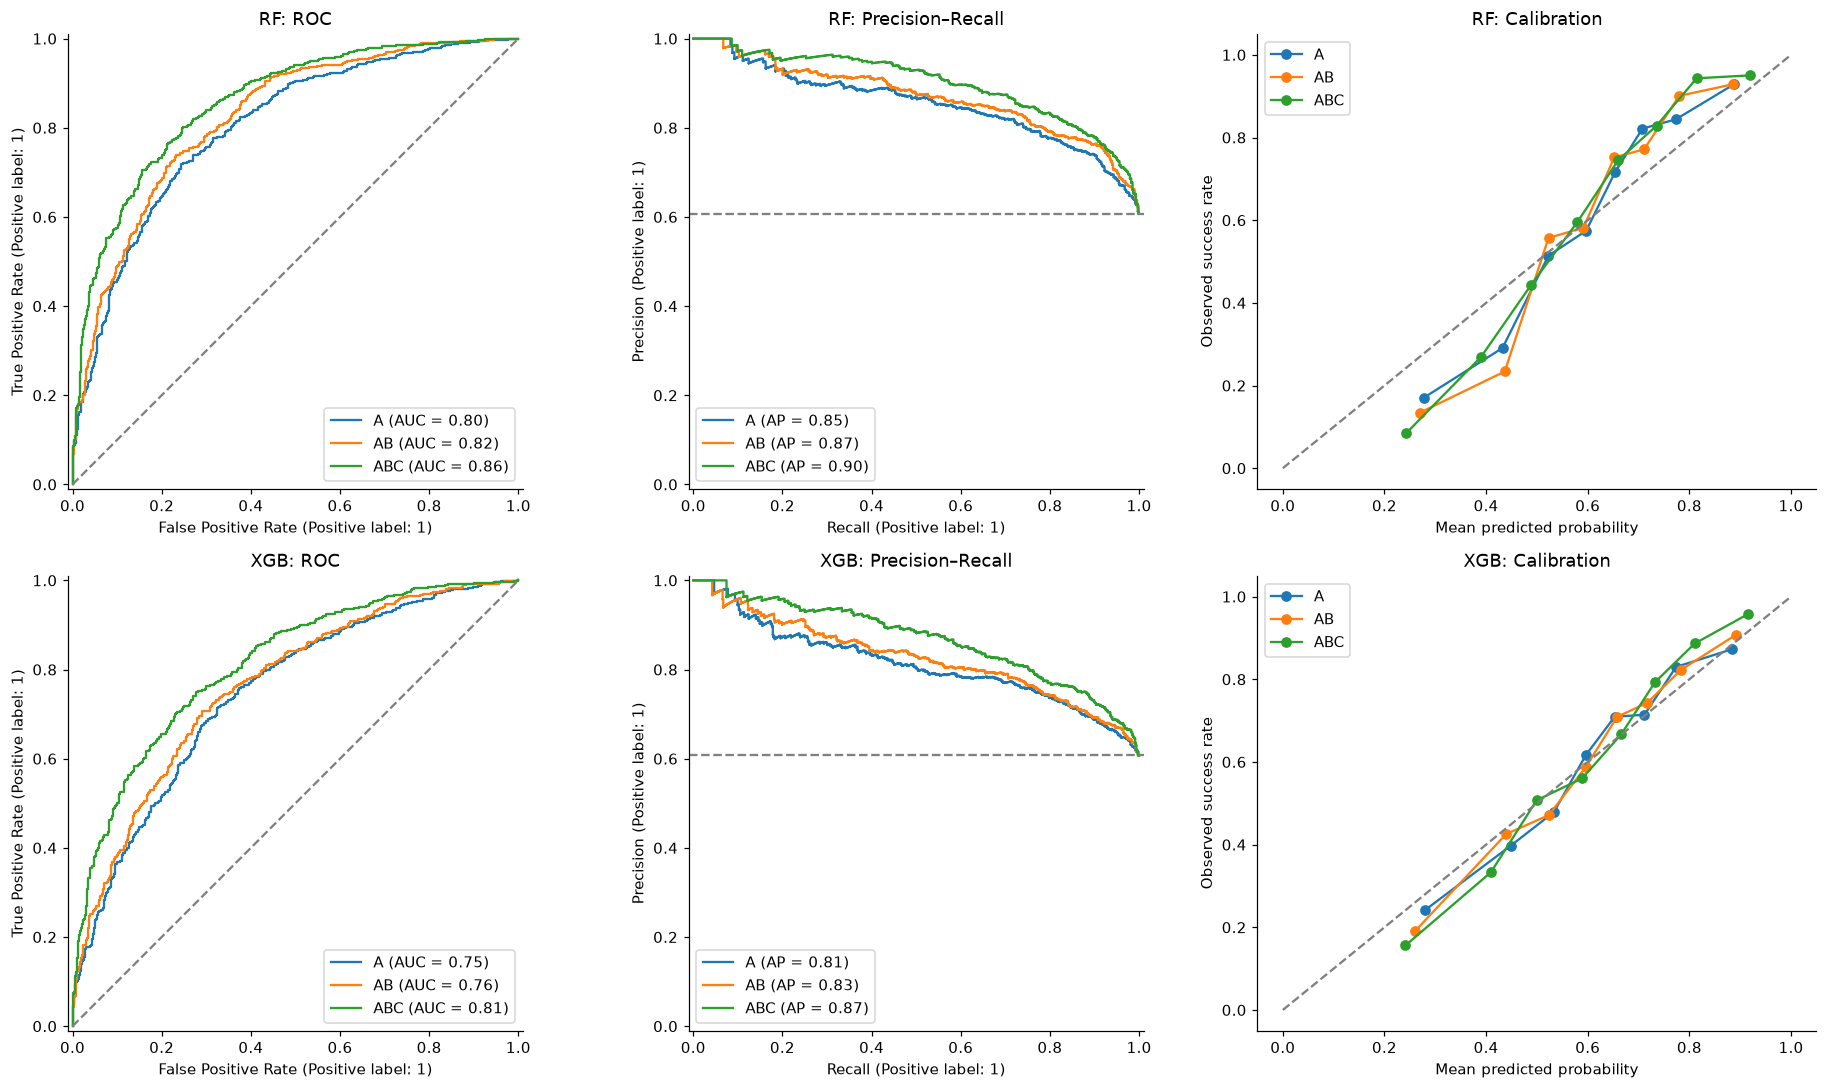

In [5]:
test_predictions = predictions.loc[predictions['split'].eq('test')].sort_values(['date', 'code']).reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for row, kind in enumerate(['RF', 'XGB']):
    for group in ['A', 'AB', 'ABC']:
        name = f'{kind}_{group}'
        p = test_predictions[f'p_{name}']
        RocCurveDisplay.from_predictions(test_predictions['Y'], p, name=group, ax=axes[row, 0])
        PrecisionRecallDisplay.from_predictions(test_predictions['Y'], p, name=group, ax=axes[row, 1])
        observed, predicted = calibration_curve(test_predictions['Y'], p, n_bins=8, strategy='quantile')
        axes[row, 2].plot(predicted, observed, marker='o', label=group)
    axes[row, 0].plot([0, 1], [0, 1], '--', color='grey')
    axes[row, 1].axhline(test_predictions['Y'].mean(), linestyle='--', color='grey')
    axes[row, 2].plot([0, 1], [0, 1], '--', color='grey')
    axes[row, 0].set_title(f'{kind}: ROC')
    axes[row, 1].set_title(f'{kind}: Precision–Recall')
    axes[row, 2].set(xlabel='Mean predicted probability', ylabel='Observed success rate', title=f'{kind}: Calibration')
    axes[row, 2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'test_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. 特征重要性

保存六组模型的内置重要性，以及验证集逐列打乱10次后的AUC下降。RF不纯度下降与XGB gain的口径不同，不直接跨算法比较；相关特征可能互相替代。

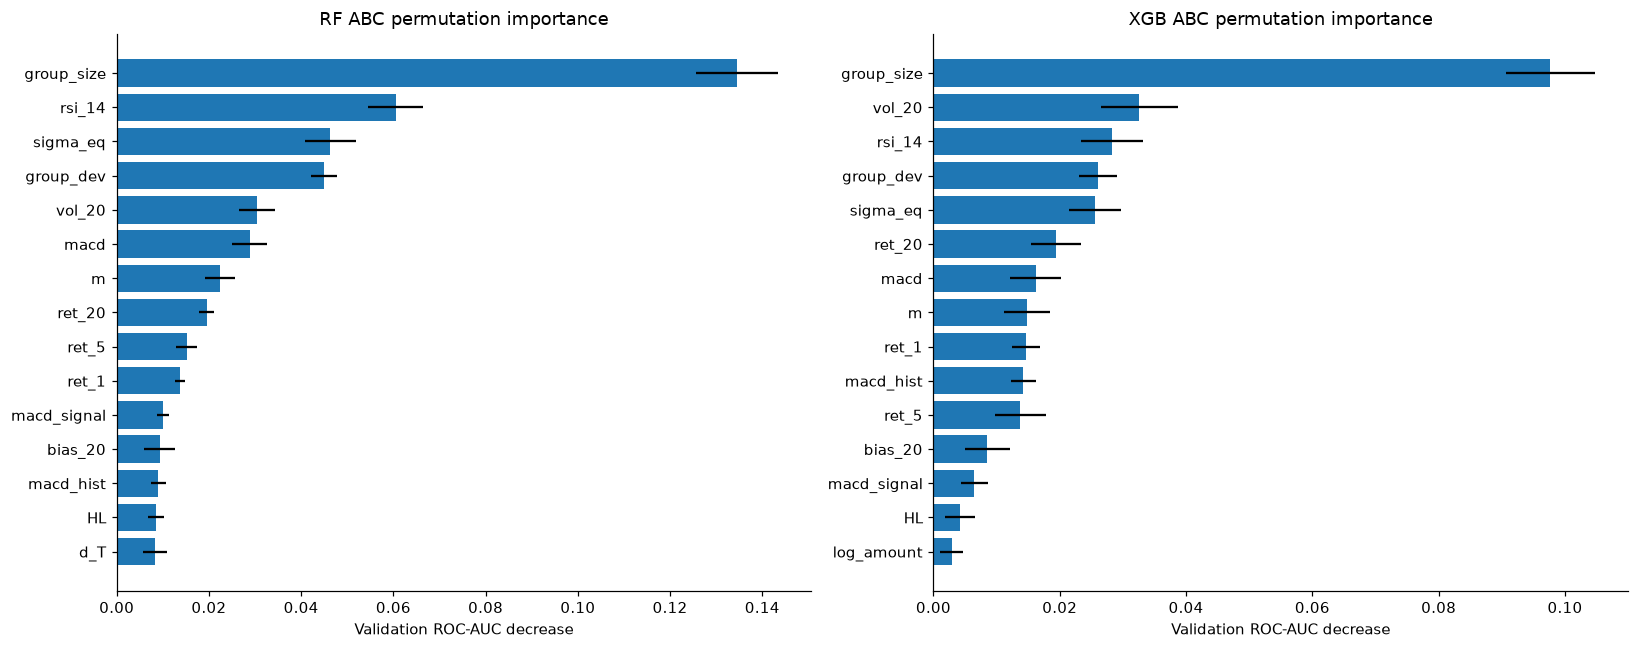

,model,feature,auc_drop_mean,auc_drop_sd
3,RF_A,vol_20,0.093033,0.005019
4,RF_A,rsi_14,0.085683,0.008469
5,RF_A,macd,0.046469,0.006065
0,RF_A,ret_1,0.043841,0.005671
7,RF_A,macd_hist,0.039239,0.004685
...,...,...,...,...
77,XGB_ABC,macd_signal,0.006434,0.002145
85,XGB_ABC,HL,0.004160,0.002371
79,XGB_ABC,log_amount,0.002900,0.001856
80,XGB_ABC,log_adv20_calc,0.001044,0.002574


In [6]:
tree_importance = pd.concat([
    pd.DataFrame({'model': name, 'feature': columns,
                  'importance': models[name].named_steps['model'].feature_importances_})
    for name, columns in feature_sets.items()
], ignore_index=True)
tree_importance['group'] = tree_importance['feature'].map(feature_table.set_index('feature')['group'])
tree_importance.sort_values(['model', 'importance'], ascending=[True, False])

importance_frames = []
for name, columns in feature_sets.items():
    result = permutation_importance(models[name], validation[columns], validation['Y'],
                                    scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=1)
    importance_frames.append(pd.DataFrame({'model': name, 'feature': columns,
                                          'auc_drop_mean': result.importances_mean,
                                          'auc_drop_sd': result.importances_std}))
permutation_table = pd.concat(importance_frames, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, kind in zip(axes, ['RF', 'XGB']):
    view = permutation_table.loc[permutation_table['model'].eq(f'{kind}_ABC')].nlargest(15, 'auc_drop_mean').sort_values('auc_drop_mean')
    ax.barh(view['feature'], view['auc_drop_mean'], xerr=view['auc_drop_sd'])
    ax.axvline(0, color='grey', linewidth=1)
    ax.set(xlabel='Validation ROC-AUC decrease', title=f'{kind} ABC permutation importance')
fig.tight_layout()
fig.savefig(FIG_DIR / 'permutation_ABC.png', dpi=160, bbox_inches='tight')
plt.show()
permutation_table.sort_values(['model', 'auc_drop_mean'], ascending=[True, False])

## 7. TreeSHAP解释ABC模型

分别解释RF_ABC与XGB_ABC，输入经过训练填补器转换。RF贡献单位为正类概率；XGB原生TreeSHAP贡献单位为log-odds，经sigmoid还原概率。代码核对贡献与预测一致，两个算法单独解释，不作因果或显著性结论。

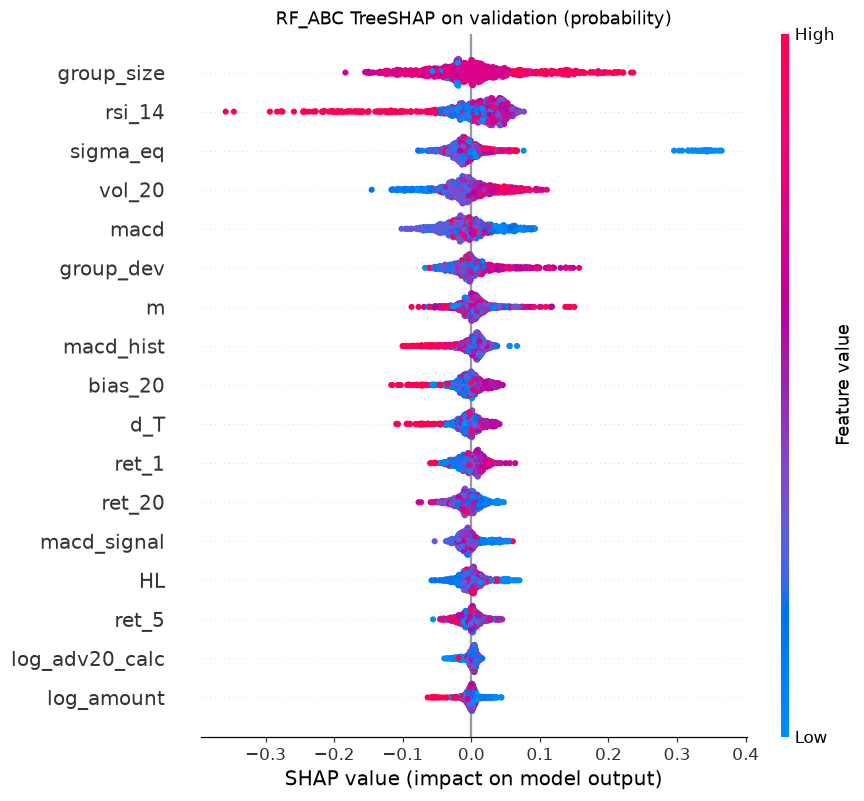

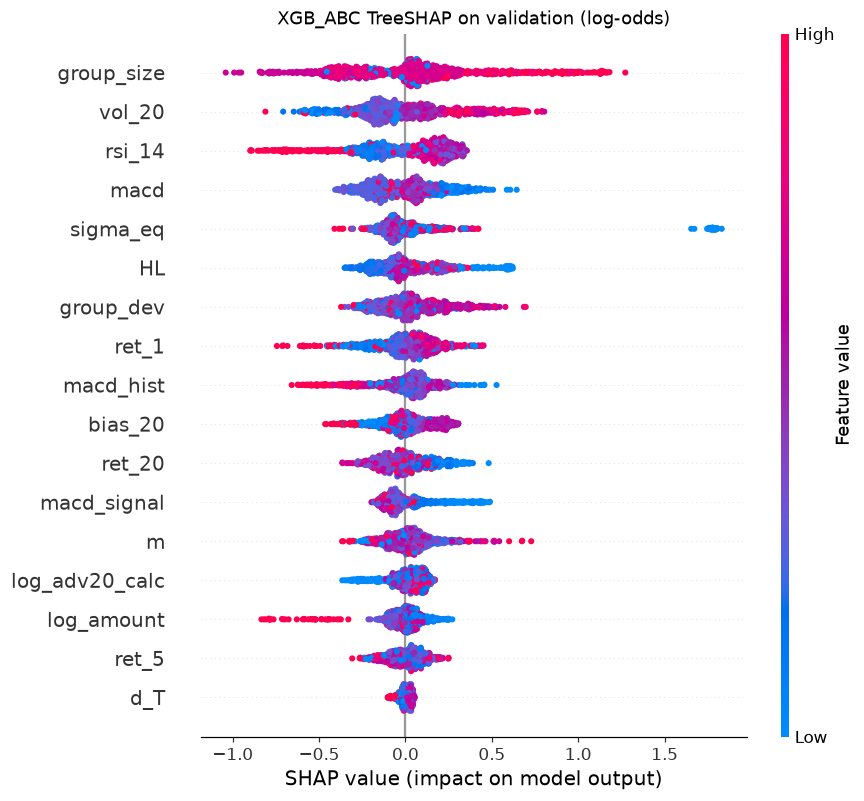

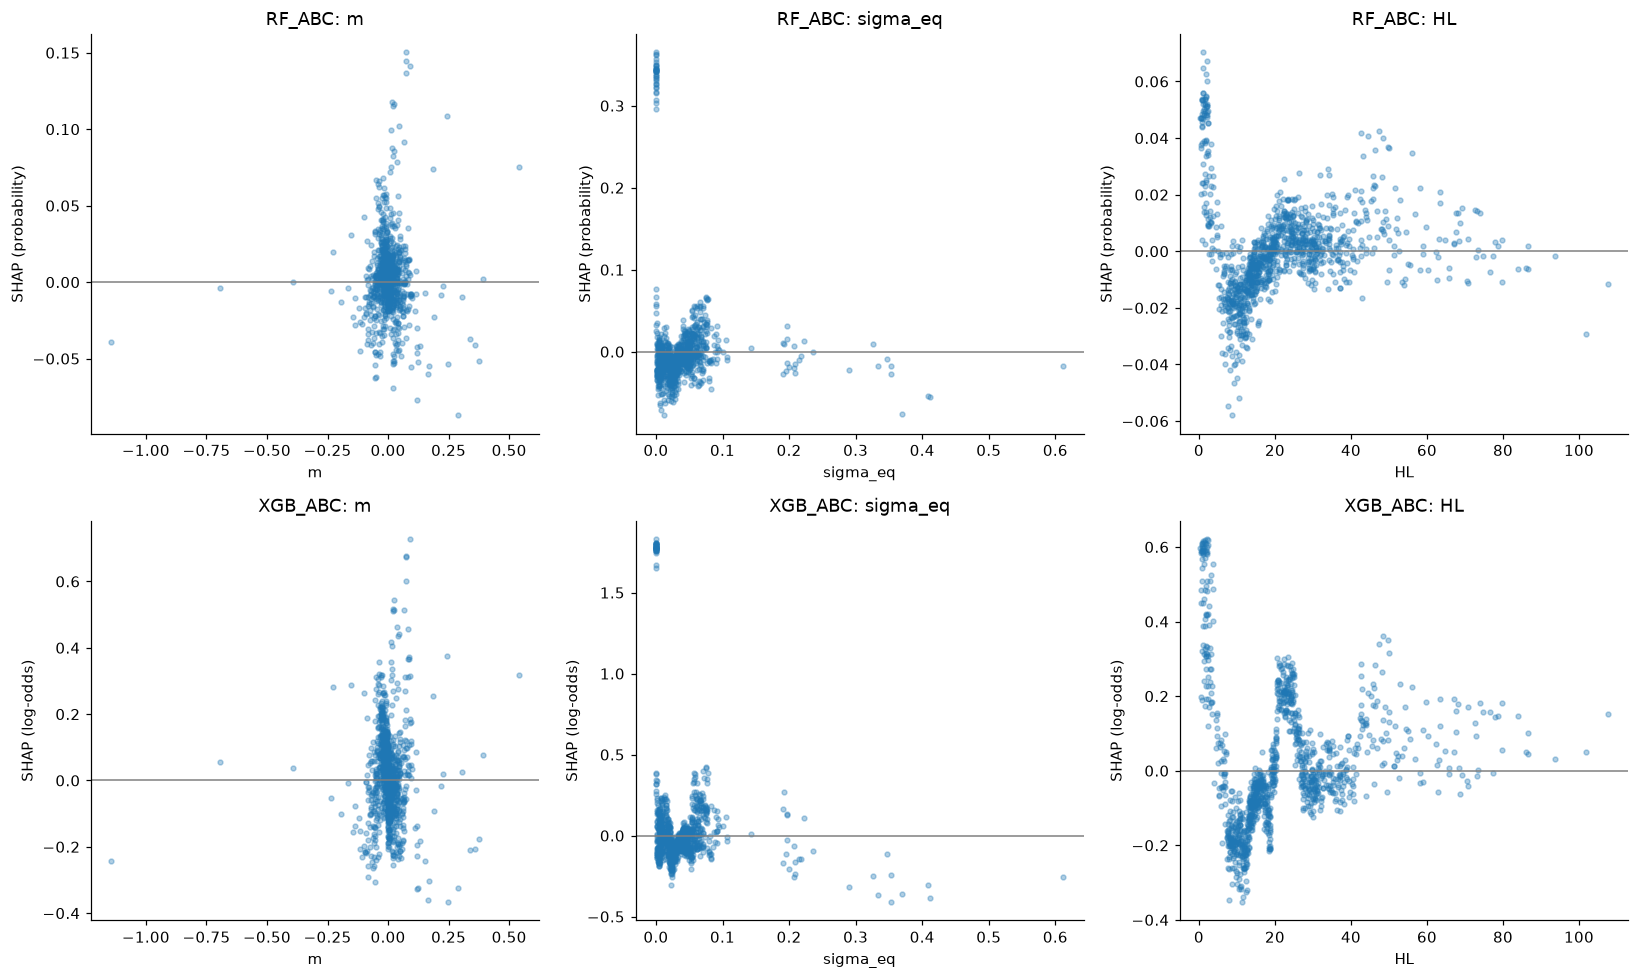

In [7]:
shap_frames, explanations, shap_units = [], {}, {}
for kind in ['RF', 'XGB']:
    name = f'{kind}_ABC'
    pipeline = models[name]
    columns = feature_sets[name]
    X_explain = pd.DataFrame(pipeline.named_steps['imputer'].transform(validation[columns]), columns=columns)
    classifier = pipeline.named_steps['model']
    if kind == 'RF':
        explainer = shap.TreeExplainer(classifier, feature_perturbation='tree_path_dependent', model_output='raw')
        values = explainer.shap_values(X_explain)[:, :, 1]
        base_values = np.full(len(X_explain), explainer.expected_value[1])
        reconstructed = base_values + values.sum(axis=1)
        unit = 'probability'
    else:
        contributions = classifier.get_booster().predict(
            DMatrix(X_explain.to_numpy(), feature_names=columns), pred_contribs=True)
        values, base_values = contributions[:, :-1], contributions[:, -1]
        reconstructed = expit(base_values + values.sum(axis=1))
        unit = 'log-odds'
    if not np.allclose(reconstructed, pipeline.predict_proba(validation[columns])[:, 1], atol=1e-5, rtol=1e-5):
        raise ValueError(f'{name}: TreeSHAP contributions do not reconstruct predictions')
    explanation = shap.Explanation(values=values, base_values=base_values,
                                   data=X_explain.to_numpy(), feature_names=columns)
    explanations[name], shap_units[name] = explanation, unit
    shap_frames.append(pd.DataFrame({'model': name, 'feature': columns, 'unit': unit,
                                     'mean_abs_shap': np.abs(values).mean(axis=0)}))
    shap.plots.beeswarm(explanation, max_display=17, show=False)
    plt.title(f'{name} TreeSHAP on validation ({unit})')
    plt.savefig(FIG_DIR / f'shap_{name}_summary.png', dpi=160, bbox_inches='tight')
    plt.show()
shap_importance = pd.concat(shap_frames, ignore_index=True)
shap_importance['group'] = shap_importance['feature'].map(feature_table.set_index('feature')['group'])
shap_importance.sort_values(['model', 'mean_abs_shap'], ascending=[True, False])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, kind in enumerate(['RF', 'XGB']):
    name = f'{kind}_ABC'
    explanation = explanations[name]
    for ax, feature in zip(axes[row], ['m', 'sigma_eq', 'HL']):
        j = explanation.feature_names.index(feature)
        ax.scatter(explanation.data[:, j], explanation.values[:, j], s=10, alpha=0.35)
        ax.axhline(0, color='grey', linewidth=1)
        ax.set(xlabel=feature, ylabel=f'SHAP ({shap_units[name]})', title=f'{name}: {feature}')
fig.tight_layout()
fig.savefig(FIG_DIR / 'shap_dependencies.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. 保存模型与结果

保存六条完整流水线、各阶段指标、特征增量、预测和解释。配置记录输入指纹、日期、随机划分、参数及依赖版本。当前实验统一写入results/tree_random/；结果说明集中在研究报告中。

In [8]:
for name, model in models.items():
    joblib.dump(model, OUT_DIR / f'{name}.joblib')
output_tables = {
    'preprocessing_summary': preprocessing_summary, 'sample_summary': sample_summary,
    'split_assignments': split_assignments, 'feature_groups': feature_table,
    'parameter_search': search_results, 'validation_selection': validation_selection,
    'model_metrics': metrics, 'event_predictions': predictions,
    'comparison_metrics': comparison_metrics, 'tree_importance': tree_importance,
    'permutation_importance': permutation_table, 'shap_importance': shap_importance
}
for name, table in output_tables.items():
    table.to_csv(OUT_DIR / f'{name}.csv', index=False, encoding='utf-8-sig')
config = {
    'dataset': 'original event data', 'input_files': INPUT_FILES, 'input_sha256': input_hashes,
    'event_date_range': [START_DATE, END_DATE], 'seed': SEED,
    'split': 'Y-stratified random 60/20/20', 'sample_count': len(events),
    'features': feature_sets, 'activity_transform': 'log1p(max(x,0))',
    'missing': 'drop nonfinite A/B; impute C using training medians',
    'selection': 'validation Log Loss, then AUC; no validation refit',
    'parameter_grids': parameter_grids, 'selected_params': selected_params,
    'threshold': THRESHOLD, 'best_validation_model': best_model_name,
    'shap_units': shap_units, 'versions': versions
}
(OUT_DIR / 'run_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

## 最终模型输入与 Summary

`final_model_tables` 保存六个模型各自实际使用的处理后数据：包含样本标识、随机划分、标签，以及该模型所用的特征。成交额已取 `log1p`，缺失值由各自已经拟合好的训练集填补器转换；这里只调用 `transform`，不重新拟合或训练。

`final_model_data` 展示验证集选出的模型对应的完整输入，以下预览前10行。`date/code/split/Y` 等用于识别和核对，不属于模型输入特征。后面的 Summary 对六个模型、三个随机子集逐一比较填补前后缺失数量，最后查看展示模型的特征分布。

In [ ]:
# 复用已有训练填补器，还原模型实际收到的数值表，不改动原始事件表。
final_model_tables, model_data_summary_rows = {}, []
for name, columns in feature_sets.items():
    processed_splits = []
    for split, frame in tables.items():
        values = models[name].named_steps['imputer'].transform(frame[columns])
        processed = frame[['sample_id', 'date', 'code', 'original_split', 'split', 'Y']].reset_index(drop=True).copy()
        processed[columns] = values
        processed_splits.append(processed)
        model_data_summary_rows.append({
            'model': name, 'split': split, 'rows': len(frame), 'features': len(columns),
            'etfs': frame['code'].nunique(), 'date_start': frame['date'].min(),
            'date_end': frame['date'].max(), 'success_rate': frame['Y'].mean(),
            'missing_before': int(frame[columns].isna().sum().sum()),
            'missing_after': int(pd.isna(values).sum()),
            'nonfinite_after': int((~np.isfinite(values)).sum())})
    final_model_tables[name] = pd.concat(processed_splits, ignore_index=True)

final_model_data = final_model_tables[best_model_name]
pd.set_option('display.max_columns', 30)
print(f'展示模型：{best_model_name}；完整数据 {len(final_model_data)} 行；特征 {len(feature_sets[best_model_name])} 项。')
final_model_data.head(10)

展示模型：RF_ABC；完整数据 5627 行；特征 17 项。


,sample_id,date,code,original_split,split,Y,ret_1,ret_5,ret_20,vol_20,rsi_14,macd,macd_signal,macd_hist,log_amount,log_adv20_calc,bias_20,d_T,m,sigma_eq,HL,group_dev,group_size
0,2023-02-02_512760,2023-02-02,512760,train,train,1,0.016594,0.009728,0.092217,0.013134,75.043717,0.015036,0.007666,0.007370,20.281848,19.772444,0.057102,0.055531,0.016781,0.031549,13.711987,0.011367,180.0
1,2025-01-13_159934,2025-01-13,159934,validation,train,0,0.001653,0.021194,0.019677,0.005493,74.195117,0.041675,0.025783,0.015892,20.689642,19.729278,0.024366,0.024074,-0.001430,0.000901,1.270576,0.101579,243.0
2,2023-09-22_512800,2023-09-22,512800,train,train,1,0.010629,0.015091,0.019574,0.008753,54.627529,0.003125,0.001243,0.001883,19.621699,19.238572,0.015160,0.015047,0.003144,0.017094,12.114855,0.018956,183.0
3,2023-12-27_159866,2023-12-27,159866,train,train,1,-0.013125,-0.004057,0.066166,0.012796,70.925792,0.019486,0.016207,0.003280,18.697267,17.378205,0.035953,0.035322,-0.033611,0.025703,12.981055,-0.001577,183.0
4,2025-03-06_159850,2025-03-06,159850,validation,train,1,0.030086,0.011038,0.148859,0.019935,64.796145,0.030511,0.031389,-0.000878,17.890858,18.479605,0.058810,0.057145,-0.056546,0.054690,32.615227,0.086654,188.0
5,2024-07-23_516970,2024-07-23,516970,train,train,1,-0.013178,-0.013178,-0.031143,0.010404,28.725373,-0.012240,-0.012190,-0.000051,17.275002,17.578691,-0.024633,-0.024941,-0.028148,0.034279,25.079499,-0.021984,174.0
6,2023-12-05_510510,2023-12-05,510510,train,train,1,-0.017710,-0.022962,-0.027608,0.007003,30.486336,-0.003888,-0.000202,-0.003686,17.446065,17.852010,-0.023298,-0.023573,-0.001328,0.001487,2.238420,0.032209,168.0
7,2025-08-08_510760,2025-08-08,510760,validation,train,0,-0.000848,0.019701,0.038034,0.005231,64.772686,0.015446,0.016105,-0.000659,17.841352,18.432479,0.014674,0.014567,-0.041444,0.020274,20.842148,0.004076,202.0
8,2023-12-21_159755,2023-12-21,159755,train,train,1,0.019452,-0.013913,-0.126501,0.014233,33.041669,-0.021851,-0.020154,-0.001697,18.672154,18.465803,-0.041544,-0.042432,0.015869,0.037494,29.159633,-0.059593,168.0
9,2023-07-19_159857,2023-07-19,159857,train,train,0,-0.014993,-0.041426,-0.025846,0.012313,36.367384,-0.001100,0.001814,-0.002914,18.824967,18.894199,-0.031125,-0.031620,0.008911,0.038441,10.574228,0.000216,203.0


In [ ]:
# Summary：每条模型流水线、每个随机子集的最终数据质量。
final_model_summary = pd.DataFrame(model_data_summary_rows)
final_model_summary

,model,split,rows,features,etfs,date_start,date_end,success_rate,missing_before,missing_after,nonfinite_after
0,RF_A,train,3376,12,315,2023-02-02,2025-12-03,0.607524,0,0,0
1,RF_A,validation,1125,12,280,2023-02-02,2025-12-03,0.608000,0,0,0
2,RF_A,test,1126,12,283,2023-02-02,2025-12-01,0.607460,0,0,0
3,RF_AB,train,3376,15,315,2023-02-02,2025-12-03,0.607524,0,0,0
4,RF_AB,validation,1125,15,280,2023-02-02,2025-12-03,0.608000,0,0,0
5,RF_AB,test,1126,15,283,2023-02-02,2025-12-01,0.607460,0,0,0
6,RF_ABC,train,3376,17,315,2023-02-02,2025-12-03,0.607524,644,0,0
7,RF_ABC,validation,1125,17,280,2023-02-02,2025-12-03,0.608000,216,0,0
8,RF_ABC,test,1126,17,283,2023-02-02,2025-12-01,0.607460,204,0,0
9,XGB_A,train,3376,12,315,2023-02-02,2025-12-03,0.607524,0,0,0


In [ ]:
# 模型输入的描述统计；仅统计特征，不混入标签和样本标识。
final_model_feature_summary = final_model_data[feature_sets[best_model_name]].describe().T
final_model_feature_summary['missing_count'] = final_model_data[feature_sets[best_model_name]].isna().sum()
final_model_feature_summary['missing_rate'] = final_model_data[feature_sets[best_model_name]].isna().mean()
final_model_feature_summary

,count,mean,std,min,25%,50%,75%,max,missing_count,missing_rate
ret_1,5627.0,0.002009,0.029136,-0.202657,-0.012516,0.000027,0.013542,1.167292,0,0.0
ret_5,5627.0,0.005616,0.064891,-0.691964,-0.026966,0.000390,0.028584,2.304422,0,0.0
ret_20,5627.0,0.012950,0.097743,-2.316146,-0.037011,0.001752,0.051082,2.306329,0,0.0
vol_20,5627.0,0.014080,0.013703,0.000005,0.008931,0.012524,0.017302,0.516277,0,0.0
rsi_14,5627.0,52.128989,20.209876,0.470237,34.989936,54.388116,68.508893,100.000000,0,0.0
macd,5627.0,0.008056,0.437448,-24.213393,-0.006617,0.001212,0.014150,21.035180,0,0.0
macd_signal,5627.0,0.006292,0.306769,-18.857668,-0.005730,0.001373,0.012974,9.528278,0,0.0
macd_hist,5627.0,0.001764,0.172941,-5.355725,-0.002796,-0.000034,0.003379,11.506902,0,0.0
log_amount,5627.0,18.848653,1.341528,13.893295,17.839834,18.579665,19.650895,24.594816,0,0.0
log_adv20_calc,5627.0,18.750356,1.307795,17.216931,17.706347,18.433526,19.539799,24.299001,0,0.0


## 最终模型评估

下表均使用本次实验结果。每个算法依次展示 A、A+B、A+B+C，便于直接比较新增特征后的表现。

ROC-AUC、Average Precision、Precision、Recall、F1 越大越好；Log Loss、Brier 越小越好。Precision、Recall、F1 的分类阈值统一为0.5。验证集用于选择模型，测试集用于最终评估。

### 验证集

In [ ]:
# 验证集：使用已计算的指标，不重新训练模型。
final_validation_evaluation = metrics.loc[metrics['split'].eq('validation'),
    ['algorithm', 'feature_set', 'roc_auc', 'average_precision', 'log_loss',
     'brier', 'precision', 'recall', 'f1']].copy()
final_validation_evaluation['feature_set'] = final_validation_evaluation['feature_set'].map(
    {'A': 'A', 'AB': 'A+B', 'ABC': 'A+B+C'})
final_validation_evaluation = final_validation_evaluation.rename(columns={
    'algorithm': '模型', 'feature_set': '特征', 'roc_auc': 'ROC-AUC',
    'average_precision': 'Average Precision', 'log_loss': 'Log Loss',
    'brier': 'Brier', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1'
}).reset_index(drop=True)
final_validation_evaluation.round(4)

,模型,特征,ROC-AUC,Average Precision,Log Loss,Brier,Precision,Recall,F1
0,RF,A,0.7609,0.8227,0.5638,0.1913,0.7237,0.8231,0.7702
1,RF,A+B,0.7856,0.8440,0.5453,0.1839,0.7373,0.8494,0.7894
2,RF,A+B+C,0.8472,0.8902,0.4935,0.1616,0.7857,0.8684,0.8250
3,XGB,A,0.7072,0.7872,0.6015,0.2083,0.6921,0.7953,0.7401
4,XGB,A+B,0.7170,0.7963,0.5915,0.2044,0.7033,0.8041,0.7503
5,XGB,A+B+C,0.7820,0.8374,0.5438,0.1829,0.7474,0.8436,0.7926


### 测试集

In [ ]:
# 测试集：使用已计算的指标，不重新训练模型。
final_test_evaluation = metrics.loc[metrics['split'].eq('test'),
    ['algorithm', 'feature_set', 'roc_auc', 'average_precision', 'log_loss',
     'brier', 'precision', 'recall', 'f1']].copy()
final_test_evaluation['feature_set'] = final_test_evaluation['feature_set'].map(
    {'A': 'A', 'AB': 'A+B', 'ABC': 'A+B+C'})
final_test_evaluation = final_test_evaluation.rename(columns={
    'algorithm': '模型', 'feature_set': '特征', 'roc_auc': 'ROC-AUC',
    'average_precision': 'Average Precision', 'log_loss': 'Log Loss',
    'brier': 'Brier', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1'
}).reset_index(drop=True)
final_test_evaluation.round(4)

,模型,特征,ROC-AUC,Average Precision,Log Loss,Brier,Precision,Recall,F1
0,RF,A,0.8024,0.8544,0.5393,0.1803,0.7432,0.8845,0.8077
1,RF,A+B,0.8246,0.8703,0.5226,0.1731,0.7623,0.9050,0.8275
2,RF,A+B+C,0.8582,0.8990,0.4849,0.1578,0.7910,0.8743,0.8306
3,XGB,A,0.7476,0.8127,0.5761,0.1966,0.7086,0.8640,0.7787
4,XGB,A+B,0.7643,0.8267,0.5620,0.1906,0.7167,0.8582,0.7811
5,XGB,A+B+C,0.8116,0.8668,0.5230,0.1743,0.7618,0.8509,0.8039
